# Experiment B: is the damage lost information, or an unfamiliar-looking image?

In `segment_amd_sd.ipynb` (Experiment A) one U-Net was trained on **grainy original** scans and tested
on denoised ones. At BM3D sigma 0.2 detection dropped and fluid area was badly underestimated. Two
possible causes:

1. **Information lost**: denoising smoothed the lesions away.
2. **Unfamiliar look**: the model never saw smooth images in training and is confused by them.

Here a new U-Net is trained **on denoised scans** and tested on denoised scans at the same sigma, so
the model knows what denoised images look like. Comparing the three set-ups separates the causes:

| Set-up | Trained on | Tested on | Measures |
|---|---|---|---|
| Baseline | original | original | normal performance |
| A | original | denoised | lost information + unfamiliar look |
| B | denoised | denoised | lost information only |

**A minus B = the part caused by the unfamiliar look.**

Done for two strengths: **sigma 0.2** (strong, where A showed damage) and **sigma 0.037** (the noise level).

**Before running:** `segment_amd_sd.ipynb` must have been run (this notebook reuses its data cache,
its trained model and its results).

**Time:** denoising the 2,346 training scans takes about 30-60 min (runs in parallel, first time only);
each U-Net takes about as long as in Experiment A (~3-4 h for 40 epochs), so ~7 h for both. Every
stage checkpoints: if anything stops, run all cells again and it continues. Set `QUICK_TEST = True`
for a ~10 min check first.

**Requires:** `torch numpy pillow scipy pandas matplotlib bm3d`.

In [1]:
from pathlib import Path
import os, sys, time, subprocess, importlib
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

QUICK_TEST = False
SIGMAS_B = ["0.2", "0.037"]       # trained in this order; strings match the denoised_cache file names
EPOCHS = 1 if QUICK_TEST else 40  # same as Experiment A
BATCH = 4                         # lower to 2 if you get an out-of-memory error
LR = 1e-3
N_WORKERS = max(1, (os.cpu_count() or 2) - 2)   # parallel BM3D processes

ROOT = Path.cwd().parent if Path.cwd().name == "_analysis" else Path.cwd()
IMG_DIR = ROOT / "images"
DENOISED = Path("denoised_cache")
SUFFIX = "_quick" if QUICK_TEST else ""
CKPT_B = Path("seg_checkpoints_B" + SUFFIX); CKPT_B.mkdir(exist_ok=True)
EVAL_B = Path("seg_eval_B" + SUFFIX); EVAL_B.mkdir(exist_ok=True)

W_PANEL, W_DEN, W_USE = 570, 560, 558   # cached BM3D images are 560 wide; models use 558
H, PAD_H, PAD_W = 380, 384, 560
CLASSES = ["background", "SRF", "IRF", "PED", "SHRM", "ISOS"]
LESIONS = ["SRF", "IRF", "PED", "SHRM"]
LESION_IDS = [CLASSES.index(c) for c in LESIONS]
IGNORE, MIN_LESION_PX = 255, 20
STRUCT = np.ones((3, 3))

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
if sys.platform == "darwin":
    subprocess.Popen(["caffeinate", "-i", "-w", str(os.getpid())])
torch.manual_seed(0); np.random.seed(0)
print("root:", ROOT, "| device:", DEVICE, "| quick test:", QUICK_TEST, "| BM3D workers:", N_WORKERS)

root: /Users/atharvax/dev/Retinal_OCT/AMD-SD | device: mps | quick test: False | BM3D workers: 8


## 1. Data and the Experiment A model

Loads the scans and decoded masks cached by the segmentation notebook, and recreates **exactly** the
same fit / tuning / validation split (same seed), so A and B are trained and tested on identical scans.

In [2]:
cache = Path("seg_cache") / "data.npz"
if not cache.exists():
    cache = Path("seg_cache") / "data_quick.npz"
assert cache.exists(), "Run segment_amd_sd.ipynb first (it creates seg_cache/data.npz)"
z = np.load(cache, allow_pickle=False)
names, imgs, masks = list(z["names"]), z["imgs"], z["masks"]
eye_of = lambda n: n.split("_")[0]
val_set = {Path(l.strip()).name for l in open(ROOT / "validation.txt") if l.strip()}
splits = np.array(["val" if n in val_set else "train" for n in names])
eyes = np.array([eye_of(n) for n in names])

rng = np.random.default_rng(0)                       # identical to segment_amd_sd.ipynb
train_eyes = np.unique(eyes[splits == "train"])
tune_eyes = set(rng.choice(train_eyes, max(1, round(0.1 * len(train_eyes))), replace=False))
idx_train = np.where((splits == "train") & ~np.isin(eyes, list(tune_eyes)))[0]
idx_tune = np.where((splits == "train") & np.isin(eyes, list(tune_eyes)))[0]
idx_val = np.where(splits == "val")[0]
if QUICK_TEST:
    idx_train, idx_tune = idx_train[:40], idx_tune[:8]
print(f"fit {len(idx_train)} | tune {len(idx_tune)} | val {len(idx_val)}  (from {cache})")

fit 2128 | tune 218 | val 703  (from seg_cache/data.npz)


In [3]:
class Block(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):   # identical to segment_amd_sd.ipynb
    def __init__(self, n_classes=len(CLASSES), base=32):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8, base * 16]
        self.downs = nn.ModuleList([Block(1, ch[0])] + [Block(ch[i], ch[i + 1]) for i in range(4)])
        self.ups = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(4))])
        self.decs = nn.ModuleList([Block(ch[i] * 2, ch[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(ch[0], n_classes, 1)
    def forward(self, x):
        skips = []
        for i, down in enumerate(self.downs):
            x = down(x if i == 0 else F.max_pool2d(x, 2)); skips.append(x)
        x = skips.pop()
        for up, dec in zip(self.ups, self.decs):
            x = dec(torch.cat([up(x), skips.pop()], 1))
        return self.head(x)

def to_input(batch_u8, mean, std):
    x = torch.from_numpy(np.ascontiguousarray(batch_u8)).float().div(255).sub(mean).div(std)[:, None]
    return F.pad(x, (0, PAD_W - W_USE, 0, PAD_H - H), mode="reflect")

def to_target(batch_u8):
    y = torch.from_numpy(np.ascontiguousarray(batch_u8)).long()
    return F.pad(y, (0, PAD_W - W_USE, 0, PAD_H - H), value=IGNORE)

@torch.no_grad()
def predict(model, batch_u8, mean, std):
    model.eval(); out = []
    for i in range(0, len(batch_u8), 4):
        logits = model(to_input(batch_u8[i:i + 4], mean, std).to(DEVICE))
        out.append(logits.argmax(1)[:, :H, :W_USE].cpu().numpy().astype(np.uint8))
    return np.concatenate(out)

# Experiment A model (trained on originals)
ckA = torch.load(Path("seg_checkpoints") / "best.pt", map_location=DEVICE, weights_only=False)
model_A = UNet(base=ckA["base"]).to(DEVICE); model_A.load_state_dict(ckA["model"])
TAG_A = f"unet{ckA['base']}_ep{ckA['epoch'] + 1}" + ("_quick" if ckA["quick"] else "")
EVAL_A = Path("seg_eval") / TAG_A
print("Experiment A model:", TAG_A, "| results in", EVAL_A, "| exists:", EVAL_A.exists())

Experiment A model: unet32_ep35 | results in seg_eval/unet32_ep35 | exists: True


## 2. Denoise the training scans

The validation scans are already in `denoised_cache/` from the exploration notebook. The training
scans are denoised here with **exactly the same BM3D settings** (log transform, same sigma, same
560-pixel crop) and saved in the same folder. Already-denoised files are skipped, so this resumes if
interrupted. Several BM3D processes run in parallel.

In [4]:
WORKER = Path("_bm3d_worker.py")
WORKER.write_text('''
import numpy as np, bm3d
from PIL import Image
from pathlib import Path

def denoise_file(args):
    src, dst, sigma = args
    if Path(dst).exists():
        return dst
    a = np.asarray(Image.open(src).convert("RGB"))[:, :560].mean(-1).astype(np.uint8)
    x = np.log1p(a.astype(np.float64)) / np.log(256.0)
    out = bm3d.bm3d(x, sigma_psd=float(sigma))
    back = np.expm1(np.clip(out, 0, 1) * np.log(256.0))
    Image.fromarray(np.clip(back, 0, 255).astype(np.uint8)).save(dst)
    return dst
''')
sys.path.insert(0, str(Path.cwd()))
import _bm3d_worker; importlib.reload(_bm3d_worker)
from concurrent.futures import ProcessPoolExecutor

def den_path(name, sigma):
    return DENOISED / f"{Path(name).stem}_s{sigma}.png"

DENOISED.mkdir(exist_ok=True)
need = [(str(IMG_DIR / eye_of(names[i]) / names[i]), str(den_path(names[i], s)), s)
        for s in SIGMAS_B for i in np.concatenate([idx_train, idx_tune]) if not den_path(names[i], s).exists()]
print(f"{len(need)} training/tuning images to denoise")
if need:
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
        for k, _ in enumerate(ex.map(_bm3d_worker.denoise_file, need, chunksize=4)):
            if (k + 1) % 200 == 0 or k + 1 == len(need):
                rate = (time.time() - t0) / (k + 1)
                print(f"{k + 1}/{len(need)}  about {rate * (len(need) - k - 1) / 60:.0f} min left")

0 training/tuning images to denoise


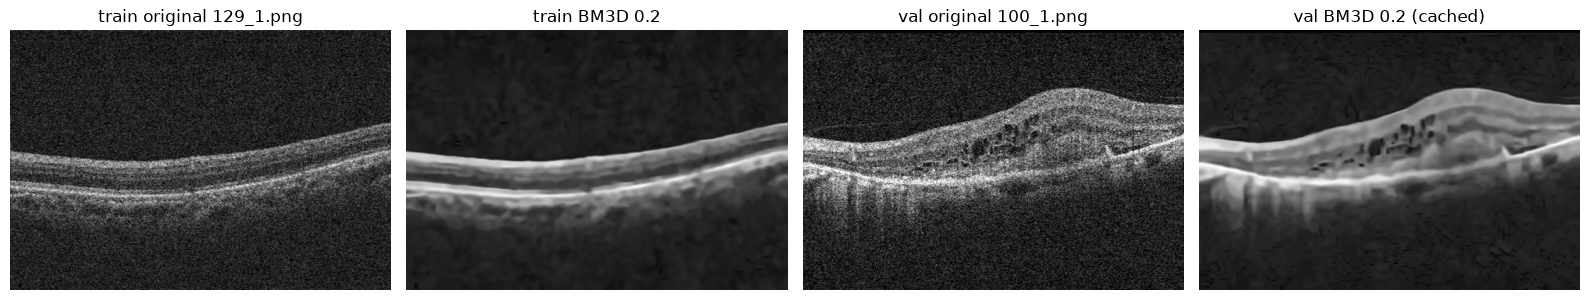

In [5]:
def load_denoised(idx, sigma):
    return np.stack([np.asarray(Image.open(den_path(names[i], sigma)).convert("L"))[:H, :W_USE] for i in idx])

# quick visual check: the training images look like the cached validation ones
i_tr, i_va = idx_train[0], idx_val[0]
fig, ax = plt.subplots(1, 4, figsize=(16, 3))
ax[0].imshow(imgs[i_tr], cmap="gray"); ax[0].set_title(f"train original {names[i_tr]}")
ax[1].imshow(load_denoised([i_tr], SIGMAS_B[0])[0], cmap="gray"); ax[1].set_title(f"train BM3D {SIGMAS_B[0]}")
ax[2].imshow(imgs[i_va], cmap="gray"); ax[2].set_title(f"val original {names[i_va]}")
ax[3].imshow(load_denoised([i_va], SIGMAS_B[0])[0], cmap="gray"); ax[3].set_title(f"val BM3D {SIGMAS_B[0]} (cached)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Train one U-Net per sigma on denoised scans

Same architecture, loss, augmentation, epochs and batch size as Experiment A; the only difference
is the input. Each model picks its best epoch on the **denoised** tuning scans. Checkpoints:
`seg_checkpoints_B/s<sigma>/last.pt` (resume) and `best.pt` (used for evaluation).

In [6]:
def dice_loss(logits, y):
    valid = (y != IGNORE); p = logits.softmax(1)
    oh = F.one_hot(torch.where(valid, y, 0), len(CLASSES)).permute(0, 3, 1, 2).float()
    v = valid[:, None].float()
    inter = (p * oh * v).sum((0, 2, 3)); denom = (p * v).sum((0, 2, 3)) + (oh * v).sum((0, 2, 3))
    return 1 - ((2 * inter + 1) / (denom + 1))[1:].mean()

def augment(xb_u8):
    x = xb_u8.astype(np.float32)
    gain = np.random.uniform(0.85, 1.15, (len(x), 1, 1)); bias = np.random.uniform(-12, 12, (len(x), 1, 1))
    return np.clip(x * gain + bias, 0, 255).astype(np.uint8)

def lesion_dice(pred, gt):
    d = []
    for c in LESION_IDS:
        p, g = pred == c, gt == c
        if g.sum() + p.sum():
            d.append(2 * (p & g).sum() / (p.sum() + g.sum()))
    return float(np.mean(d))

def train_on_denoised(sigma):
    out_dir = CKPT_B / f"s{sigma}"; out_dir.mkdir(exist_ok=True)
    X_fit, X_tune = load_denoised(idx_train, sigma), load_denoised(idx_tune, sigma)
    Y_fit, Y_tune = masks[idx_train], masks[idx_tune]
    mean, std = float(X_fit.mean()) / 255, float(X_fit.std()) / 255
    torch.manual_seed(0); np.random.seed(0)
    model = UNet(base=32).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, epochs=EPOCHS,
                                                steps_per_epoch=int(np.ceil(len(X_fit) / BATCH)))
    start, best, log = 0, -1.0, []
    if (out_dir / "last.pt").exists():
        ck = torch.load(out_dir / "last.pt", map_location=DEVICE, weights_only=False)
        if ck.get("epochs") == EPOCHS:
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
            start, best, log = ck["epoch"] + 1, ck["best"], ck["log"]
            print(f"sigma {sigma}: resuming after epoch {start}")
    for epoch in range(start, EPOCHS):
        model.train(); t0, losses = time.time(), []
        perm = np.random.permutation(len(X_fit))
        for b in range(0, len(perm), BATCH):
            ib = perm[b:b + BATCH]
            xb, yb = X_fit[ib], Y_fit[ib]
            flip = np.random.rand(len(ib)) < 0.5
            xb[flip], yb[flip] = xb[flip][:, :, ::-1], yb[flip][:, :, ::-1]
            x, y = to_input(augment(xb), mean, std).to(DEVICE), to_target(yb).to(DEVICE)
            logits = model(x)
            loss = F.cross_entropy(logits, y, ignore_index=IGNORE) + dice_loss(logits, y)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            losses.append(loss.item())
        td = lesion_dice(predict(model, X_tune, mean, std), Y_tune)
        log.append({"epoch": epoch + 1, "loss": float(np.mean(losses)), "tune_dice": td})
        if td > best:
            best = td
            torch.save({"model": model.state_dict(), "epoch": epoch, "tune_dice": td, "mean": mean, "std": std},
                       out_dir / "best.pt")
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "epoch": epoch, "best": best, "log": log, "epochs": EPOCHS}, out_dir / "last.pt")
        print(f"sigma {sigma}  epoch {epoch + 1}/{EPOCHS}  loss {log[-1]['loss']:.3f}  "
              f"tuning Dice {td:.3f}{'  (best)' if td == best else ''}  {time.time() - t0:.0f}s")
    return out_dir

for s in SIGMAS_B:
    train_on_denoised(s)

sigma 0.2: resuming after epoch 40
sigma 0.037: resuming after epoch 30
sigma 0.037  epoch 31/40  loss 0.260  tuning Dice 0.831  (best)  278s
sigma 0.037  epoch 32/40  loss 0.241  tuning Dice 0.817  308s
sigma 0.037  epoch 33/40  loss 0.238  tuning Dice 0.836  (best)  320s
sigma 0.037  epoch 34/40  loss 0.235  tuning Dice 0.832  325s
sigma 0.037  epoch 35/40  loss 0.233  tuning Dice 0.839  (best)  330s
sigma 0.037  epoch 36/40  loss 0.227  tuning Dice 0.825  335s
sigma 0.037  epoch 37/40  loss 0.220  tuning Dice 0.825  336s
sigma 0.037  epoch 38/40  loss 0.222  tuning Dice 0.830  347s
sigma 0.037  epoch 39/40  loss 0.219  tuning Dice 0.827  337s
sigma 0.037  epoch 40/40  loss 0.220  tuning Dice 0.828  339s


## 4. Evaluate on the validation scans

For each sigma, on the same validation scans and lesions as Experiment A:
- **B**: the denoised-trained model on denoised scans (matched)
- **A**: the original-trained model on the same denoised scans (re-scored here so both use identical code)

Predicted label maps are saved too (`seg_eval_B/preds_*.npz`): they are what the
model-disagreement warning (the next idea) will use.

In [7]:
def score_scan(pred, gt):   # identical to segment_amd_sd.ipynb
    lesion_rows, scan_rows = [], []
    for c in LESIONS:
        k = CLASSES.index(c); g, p = gt == k, pred == k
        comp, n = ndimage.label(g, STRUCT); halo = ndimage.binary_dilation(g, iterations=2)
        if n:
            areas = ndimage.sum(g, comp, range(1, n + 1))
            dil = [ndimage.binary_dilation(comp == j, iterations=3) for j in range(1, n + 1)]
            for j in range(n):
                area = int(areas[j])
                if area < MIN_LESION_PX:
                    continue
                les = comp == j + 1
                others = np.zeros_like(g)
                for q in range(n):
                    if q != j:
                        others |= comp == q + 1
                cov = (p & les).sum() / area
                lesion_rows.append({"class": c, "area_px": area, "coverage": cov, "detected": cov >= 0.10,
                                    "area_ratio": (p & dil[j] & ~others).sum() / area})
        pc, pn = ndimage.label(p, STRUCT); invented = 0
        if pn:
            pareas = ndimage.sum(p, pc, range(1, pn + 1)); touched = set(np.unique(pc[halo & p])) - {0}
            invented = sum(1 for j in range(pn) if pareas[j] >= MIN_LESION_PX and (j + 1) not in touched)
        scan_rows.append({"class": c, "gt_px": int(g.sum()), "pred_px": int(p.sum()),
                          "inter_px": int((p & g).sum()), "invented": invented})
    return lesion_rows, scan_rows

eval_idx = [i for i in idx_val if all(den_path(names[i], s).exists() for s in SIGMAS_B)]
if QUICK_TEST:
    eval_idx = eval_idx[:12]
print(f"evaluating on {len(eval_idx)} validation scans")

def evaluate(model, mean, std, images, label):
    les_f, scan_f, pred_f = EVAL_B / f"lesions_{label}.csv", EVAL_B / f"scans_{label}.csv", EVAL_B / f"preds_{label}.npz"
    if les_f.exists() and scan_f.exists() and pred_f.exists():
        print(f"{label}: already evaluated"); return
    preds = predict(model, images, mean, std)
    L, S = [], []
    for i, pr in zip(eval_idx, preds):
        lr, sr = score_scan(pr, masks[i]); meta = {"image": names[i], "eye": eyes[i], "setup": label}
        L += [meta | r for r in lr]; S += [meta | r for r in sr]
    pd.DataFrame(L).to_csv(les_f, index=False); pd.DataFrame(S).to_csv(scan_f, index=False)
    np.savez_compressed(pred_f, names=np.array([names[i] for i in eval_idx]), preds=preds)
    print(f"{label}: {len(L)} lesions scored")

evaluate(model_A, ckA["mean"], ckA["std"], imgs[eval_idx], "baseline")
for s in SIGMAS_B:
    X = load_denoised(eval_idx, s)
    ckB = torch.load(CKPT_B / f"s{s}" / "best.pt", map_location=DEVICE, weights_only=False)
    model_B = UNet(base=32).to(DEVICE); model_B.load_state_dict(ckB["model"])
    print(f"sigma {s}: B model from epoch {ckB['epoch'] + 1}, tuning Dice {ckB['tune_dice']:.3f}")
    evaluate(model_A, ckA["mean"], ckA["std"], X, f"A_s{s}")
    evaluate(model_B, ckB["mean"], ckB["std"], X, f"B_s{s}")

evaluating on 626 validation scans
baseline: 2001 lesions scored
sigma 0.2: B model from epoch 28, tuning Dice 0.829
A_s0.2: 2001 lesions scored
B_s0.2: 2001 lesions scored
sigma 0.037: B model from epoch 35, tuning Dice 0.839
A_s0.037: 2001 lesions scored
B_s0.037: 2001 lesions scored


## 5. Results

### 5a. Detection rate by lesion size: baseline vs A vs B

In [8]:
BINS = [20, 50, 200, 1000, 5000, np.inf]
BIN_LABELS = ["20-50", "50-200", "200-1k", "1k-5k", ">5k"]
SETUPS = ["baseline"] + [f"{x}_s{s}" for s in SIGMAS_B for x in ("A", "B")]
les = {k: pd.read_csv(EVAL_B / f"lesions_{k}.csv", dtype={"eye": str}) for k in SETUPS}
scn = {k: pd.read_csv(EVAL_B / f"scans_{k}.csv", dtype={"eye": str}) for k in SETUPS}
ref = les["baseline"]
for k in SETUPS:   # same lesions, same order in every set-up
    assert (les[k][["image", "class", "area_px"]].values == ref[["image", "class", "area_px"]].values).all()
size_bin = pd.cut(ref["area_px"], BINS, labels=BIN_LABELS, right=False).rename("size_bin")

def table(col, agg):
    t = pd.DataFrame({k: les[k][col].astype(float).groupby(size_bin, observed=False).agg(agg) for k in SETUPS})
    t["n"] = ref.groupby(size_bin, observed=False).size()
    return t

det = table("detected", "mean")
print("Detection rate (share of expert lesions found)")
det.round(3)

Detection rate (share of expert lesions found)


,baseline,A_s0.2,B_s0.2,A_s0.037,B_s0.037,n
size_bin,,,,,,
20-50,0.593,0.435,0.528,0.593,0.454,108
50-200,0.757,0.554,0.749,0.754,0.735,370
200-1k,0.864,0.591,0.852,0.855,0.853,633
1k-5k,0.954,0.732,0.936,0.957,0.935,582
>5k,0.977,0.805,0.974,0.974,0.977,308


### 5b. Measured size and total fluid area

Median area ratio per lesion (1 = correct size) and median total-area error per scan and class.

In [9]:
print("Median area ratio (1 = correct size)")
print(table("area_ratio", "median").round(2).to_string())

rows = []
for k in SETUPS:
    for c in LESIONS:
        sc = scn[k][scn[k]["class"] == c]; has = sc[sc.gt_px >= 50]
        rows.append({"setup": k, "class": c,
                     "dice": 2 * sc.inter_px.sum() / max(sc.pred_px.sum() + sc.gt_px.sum(), 1),
                     "total_area_error": ((has.pred_px - has.gt_px) / has.gt_px).median(),
                     "false_pos_per_scan": sc.invented.mean()})
summ = pd.DataFrame(rows)
for col in ["dice", "total_area_error", "false_pos_per_scan"]:
    print(f"\n{col}"); print(summ.pivot(index="class", columns="setup", values=col)[SETUPS].round(3).to_string())

Median area ratio (1 = correct size)
          baseline  A_s0.2  B_s0.2  A_s0.037  B_s0.037    n
size_bin                                                   
20-50         0.71    0.00    0.25      0.76      0.00  108
50-200        1.02    0.55    1.08      1.03      0.91  370
200-1k        0.92    0.37    0.96      0.92      0.90  633
1k-5k         0.94    0.57    0.93      0.93      0.92  582
>5k           0.85    0.31    0.86      0.83      0.87  308

dice
setup  baseline  A_s0.2  B_s0.2  A_s0.037  B_s0.037
class                                              
IRF       0.812   0.595   0.783     0.800     0.811
PED       0.768   0.553   0.747     0.762     0.780
SHRM      0.693   0.375   0.684     0.685     0.702
SRF       0.792   0.701   0.784     0.789     0.791

total_area_error
setup  baseline  A_s0.2  B_s0.2  A_s0.037  B_s0.037
class                                              
IRF       0.031   0.051   0.100     0.059     0.048
PED      -0.002  -0.647  -0.003     0.027    -0.083

### 5c. Splitting the damage: lost information vs unfamiliar look

For each sigma, drop in detection relative to the baseline:
- **total (A)** = baseline - A
- **lost information (B)** = baseline - B
- **unfamiliar look (A - B)** = B - A

with 95% intervals from resampling whole eyes, for small (< 200 px), large (>= 1000 px) and all lesions.

In [10]:
eye_ids = ref["eye"].unique()
pos = {e: np.where(ref["eye"].to_numpy() == e)[0] for e in eye_ids}
groups = {"small": (ref.area_px < 200).to_numpy(), "large": (ref.area_px >= 1000).to_numpy(),
          "all": np.ones(len(ref), bool)}
D = {k: les[k]["detected"].to_numpy().astype(float) for k in SETUPS}
rng_b = np.random.default_rng(42)
boot_picks = [np.concatenate([pos[e] for e in rng_b.choice(eye_ids, len(eye_ids), replace=True)]) for _ in range(1000)]

def ci(f):
    vals = [f(p) for p in boot_picks]
    lo, hi = np.nanpercentile(vals, [2.5, 97.5])
    return f"{f(np.arange(len(ref))):+.3f} [{lo:+.3f}, {hi:+.3f}]"

rows = []
for s in SIGMAS_B:
    a, b = D[f"A_s{s}"], D[f"B_s{s}"]
    for gname, g in groups.items():
        rows.append({"sigma": s, "lesions": gname, "n": int(g.sum()),
                     "total drop (A)": ci(lambda p: D["baseline"][p][g[p]].mean() - a[p][g[p]].mean()),
                     "lost information (B)": ci(lambda p: D["baseline"][p][g[p]].mean() - b[p][g[p]].mean()),
                     "unfamiliar look (A-B)": ci(lambda p: b[p][g[p]].mean() - a[p][g[p]].mean())})
split = pd.DataFrame(rows)
split.to_csv(EVAL_B / "damage_split.csv", index=False)
print("Drop in detection rate, with 95% CI (positive = worse than baseline)")
split

Drop in detection rate, with 95% CI (positive = worse than baseline)


,sigma,lesions,n,total drop (A),lost information (B),unfamiliar look (A-B)
0,0.2,small,478,"+0.192 [+0.109, +0.313]","+0.021 [-0.027, +0.103]","+0.172 [+0.121, +0.255]"
1,0.2,large,890,"+0.204 [+0.130, +0.293]","+0.012 [-0.012, +0.044]","+0.192 [+0.113, +0.289]"
2,0.2,all,2001,"+0.223 [+0.158, +0.295]","+0.014 [-0.006, +0.040]","+0.209 [+0.154, +0.278]"
3,0.037,small,478,"+0.002 [-0.012, +0.014]","+0.048 [+0.013, +0.108]","-0.046 [-0.107, -0.012]"
4,0.037,large,890,"-0.001 [-0.008, +0.006]","+0.012 [+0.000, +0.033]","-0.013 [-0.039, +0.003]"
5,0.037,all,2001,"+0.003 [-0.003, +0.009]","+0.020 [+0.006, +0.039]","-0.017 [-0.036, -0.002]"


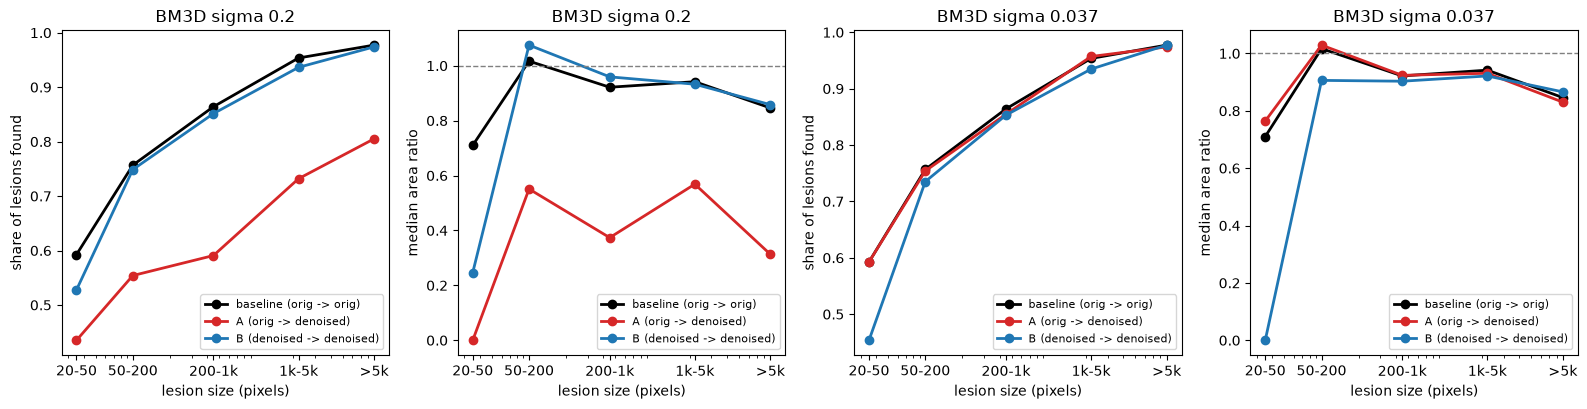

In [11]:
fig, axes = plt.subplots(1, 2 * len(SIGMAS_B), figsize=(8 * len(SIGMAS_B), 4.2))
centres = [35, 100, 450, 2200, 9000]
area_t = table("area_ratio", "median")
for j, s in enumerate(SIGMAS_B):
    for ax, tab, ylab in [(axes[2 * j], det, "share of lesions found"), (axes[2 * j + 1], area_t, "median area ratio")]:
        for k, style in [("baseline", "k-"), (f"A_s{s}", "C3-"), (f"B_s{s}", "C0-")]:
            lab = {"baseline": "baseline (orig -> orig)", f"A_s{s}": "A (orig -> denoised)", f"B_s{s}": "B (denoised -> denoised)"}[k]
            ax.plot(centres, tab[k], style, marker="o", lw=2, label=lab)
        ax.set_xscale("log"); ax.set_xticks(centres); ax.set_xticklabels(BIN_LABELS)
        ax.set_xlabel("lesion size (pixels)"); ax.set_ylabel(ylab); ax.set_title(f"BM3D sigma {s}"); ax.legend(fontsize=8)
    axes[2 * j + 1].axhline(1, color="grey", ls="--", lw=1)
plt.tight_layout(); plt.savefig(EVAL_B / "experiment_B.png", dpi=150); plt.show()

### How to read Experiment B

- **B close to baseline** (blue line on the black one): the denoised scans still contain the lesions;
  A's damage came from the model never having seen smooth images. Lesson: *a model must be trained
  on the same kind of images it is used on*; the denoising itself was not destroying information.
- **B close to A** (blue on red): the information is genuinely gone; retraining cannot recover it.
- **In between:** both causes contribute; the table in 5c gives each share with confidence intervals.
- Check **small vs large** in 5c: if the lost-information part is larger for small lesions, that is
  the size effect (H2) on the clinical measure, once the unfamiliar-look effect is removed.
- The saved prediction files (`preds_A_*`, `preds_B_*`) are the input for the next step: flagging
  lesions where the two models disagree.